/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()



[VAL]  N=477  Classes=4
ECE        : 0.009690
Brier Score: 0.058287

[TEST]  N=481  Classes=4
ECE        : 0.021510
Brier Score: 0.070982


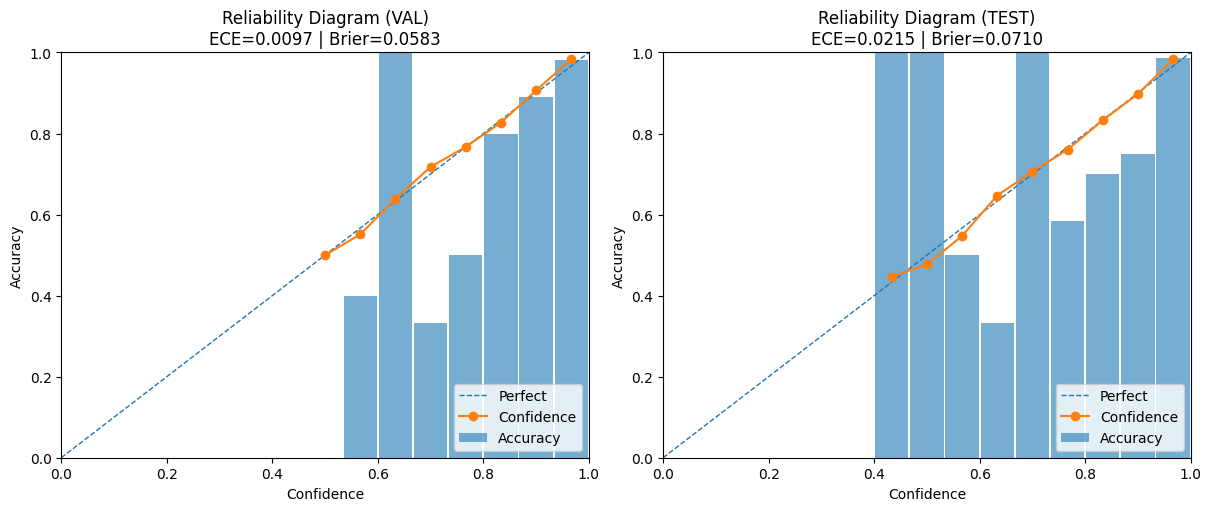

In [3]:
# Calibration + Reliability (ECE + Reliability Diagram) + Brier Score
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.utils import to_categorical

def calibration_metrics(probs, y_true, n_bins=15):
    probs = np.asarray(probs, dtype=np.float32)
    y_true = np.asarray(y_true, dtype=np.int64)
    n = len(y_true)
    k = probs.shape[1]

    conf = probs.max(axis=1)
    pred = probs.argmax(axis=1)
    correct = (pred == y_true).astype(np.float32)

    bins = np.linspace(0.0, 1.0, n_bins + 1)
    # bin id in [0, n_bins-1]
    bin_ids = np.clip(np.digitize(conf, bins, right=True) - 1, 0, n_bins - 1)

    bin_count = np.bincount(bin_ids, minlength=n_bins).astype(np.int64)
    bin_acc = np.full(n_bins, np.nan, dtype=np.float32)
    bin_conf = np.full(n_bins, np.nan, dtype=np.float32)

    for b in range(n_bins):
        m = (bin_ids == b)
        if np.any(m):
            bin_acc[b] = float(correct[m].mean())
            bin_conf[b] = float(conf[m].mean())

    nonempty = bin_count > 0
    ece = float(np.sum(np.abs(bin_acc[nonempty] - bin_conf[nonempty]) * (bin_count[nonempty] / n)))

    y_onehot = to_categorical(y_true, num_classes=k).astype(np.float32)
    brier = float(np.mean(np.sum((probs - y_onehot) ** 2, axis=1)))

    return {
        "ECE": ece,
        "Brier": brier,
        "bin_edges": bins,
        "bin_centers": (bins[:-1] + bins[1:]) / 2.0,
        "bin_acc": bin_acc,
        "bin_conf": bin_conf,
        "bin_count": bin_count,
        "n": n,
        "k": k,
    }

def plot_reliability(ax, m, title):
    centers = m["bin_centers"]
    width = (m["bin_edges"][1] - m["bin_edges"][0]) * 0.95

    ax.plot([0, 1], [0, 1], "--", linewidth=1, label="Perfect")
    ax.bar(centers, np.nan_to_num(m["bin_acc"], nan=0.0), width=width, alpha=0.6, label="Accuracy")
    ax.plot(centers, m["bin_conf"], marker="o", label="Confidence")

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_xlabel("Confidence")
    ax.set_ylabel("Accuracy")
    ax.set_title(title)
    ax.legend(loc="lower right")

def _get_probs_and_true(split_name):
    # Prefer precomputed probs_* and y_true_* if you already made them
    key_p = f"probs_{split_name.lower()}"
    key_y = f"y_true_{split_name.lower()}"
    if key_p in globals() and key_y in globals():
        return globals()[key_p], globals()[key_y], split_name

    # Else fall back to *_gen_plain if present
    key_g = f"{split_name.lower()}_gen_plain"
    if key_g in globals():
        gen = globals()[key_g]
        p = model.predict(gen, verbose=0)
        y = gen.classes
        return p, y, split_name

    return None, None, split_name

# ---- Run on VAL + TEST if available (works even if only one exists) ----
splits = []
for name in ["VAL", "TEST"]:
    p, y, disp = _get_probs_and_true(name)
    if p is not None and y is not None:
        splits.append((disp, p, y))

assert len(splits) > 0, "Couldn't find (probs_*/y_true_*) or (*_gen_plain). Make sure you ran evaluation cells first."

# Compute + print
metrics = {}
for disp, p, y in splits:
    m = calibration_metrics(p, y, n_bins=15)
    metrics[disp] = m
    print(f"\n[{disp}]  N={m['n']}  Classes={m['k']}")
    print(f"ECE        : {m['ECE']:.6f}")
    print(f"Brier Score: {m['Brier']:.6f}")

# Plot reliability diagrams
fig, axes = plt.subplots(1, len(splits), figsize=(6 * len(splits), 5), constrained_layout=True)
if len(splits) == 1:
    axes = [axes]
for ax, (disp, _, _) in zip(axes, splits):
    m = metrics[disp]
    plot_reliability(ax, m, f"Reliability Diagram ({disp})\nECE={m['ECE']:.4f} | Brier={m['Brier']:.4f}")
plt.show()